# Deep Hedging of American Digital Options: 5 Recurrent Architectures (JAX Backend)
This notebook trains neural network deep hedging agents for an American Digital option ($H = -1$ if $S_t > 0.95$ for all $t$, else $0$).
Evaluates 5 recurrence architectural configurations:
1. `am_dig_none`: Non-recurrent feedforward benchmark
2. `am_dig_digital`: Digital memory states (past_repr=5, event=5)
3. `am_dig_standard`: Standard aggregate recurrence (aggregate=5)
4. `am_dig_mix_relu`: Mixed recurrence (aggregate=2, past_repr=2) with ReLU activation (width=100)
5. `am_dig_mix_softplus`: Mixed recurrence (aggregate=2, past_repr=2) with Softplus activation (width=100)

**Backend**: JAX / Flax functional engine.
**Self-contained**: Uses local `dh_jax` module.


In [1]:
import os, sys, math
from pathlib import Path
from dataclasses import replace

NB_DIR = Path.cwd()
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from dh_jax.world import WorldConfig, simulate
from dh_jax.model import AgentConfig, GymConfig, oce_utility
from dh_jax.train import TrainConfig, fit
from dh_jax.plotting import plot_training
from dh_jax.stats import mean_bins
from dh_jax.fd import bs_fd
from configs.catalog import get_config

MODE = os.environ.get("DH_MODE", "original")
def get_epochs(default_ep):
    if os.environ.get("DH_EPOCHS"):
        return int(os.environ.get("DH_EPOCHS"))
    return 2 if MODE == "smoke" else default_ep

def get_samples(default_samples):
    return min(default_samples, 500) if MODE == "smoke" else default_samples

CHECKPOINTS = os.environ.get("DH_CHECKPOINTS", "checkpoints") or None
print(f"trainer-american_digital.ipynb initialized | Mode: {MODE}")


trainer-american_digital.ipynb initialized | Mode: smoke


## Payoff and World Setup
American Digital Option with knock-out barrier at 0.95.


In [2]:
barrier = 0.95
def payoff_def(spots):
    notko = np.cumprod(np.where(spots > barrier, 1.0, 0.0), axis=1)
    terminal = 1.0
    return dict(payoff=-terminal * notko[:, -1], features=notko[:, :-1])

payoff_def.name = f"American Digital @ {barrier}"

cfg_ref = get_config("am_dig_none", mode=MODE)
n_samples = get_samples(cfg_ref["samples"])
n_epochs = get_epochs(cfg_ref["epochs"])

world_cfg = WorldConfig(
    steps=cfg_ref["steps"],
    dt=cfg_ref["dt"],
    samples=n_samples,
    drift=cfg_ref["drift"],
    cost_s=cfg_ref["cost_s"],
    black_scholes=True,
    payoff=payoff_def
)

train_cfg = TrainConfig(
    epochs=n_epochs,
    batch_size=min(cfg_ref["batch_size"], n_samples),
    learning_rate=cfg_ref["lr"],
    clipvalue=cfg_ref["clipvalue"],
    global_clipnorm=cfg_ref["global_clipnorm"]
)

print(f"Simulating American Digital World: {n_samples} samples, {cfg_ref['steps']} steps...")
world = simulate(world_cfg)
val_world = world.clone(samples=max(n_samples // 2, 50), seed=1)


Simulating American Digital World: 500 samples, 100 steps...


## Training 5 Recurrent Architecture Variants


--- Training American Digital: none (epochs=2) ---


  epoch 1/2: loss 3.03913 val 2.97080 best@1 (2.06s)


  epoch 2/2: loss 0.67213 val 0.79738 best@2 (0.45s)


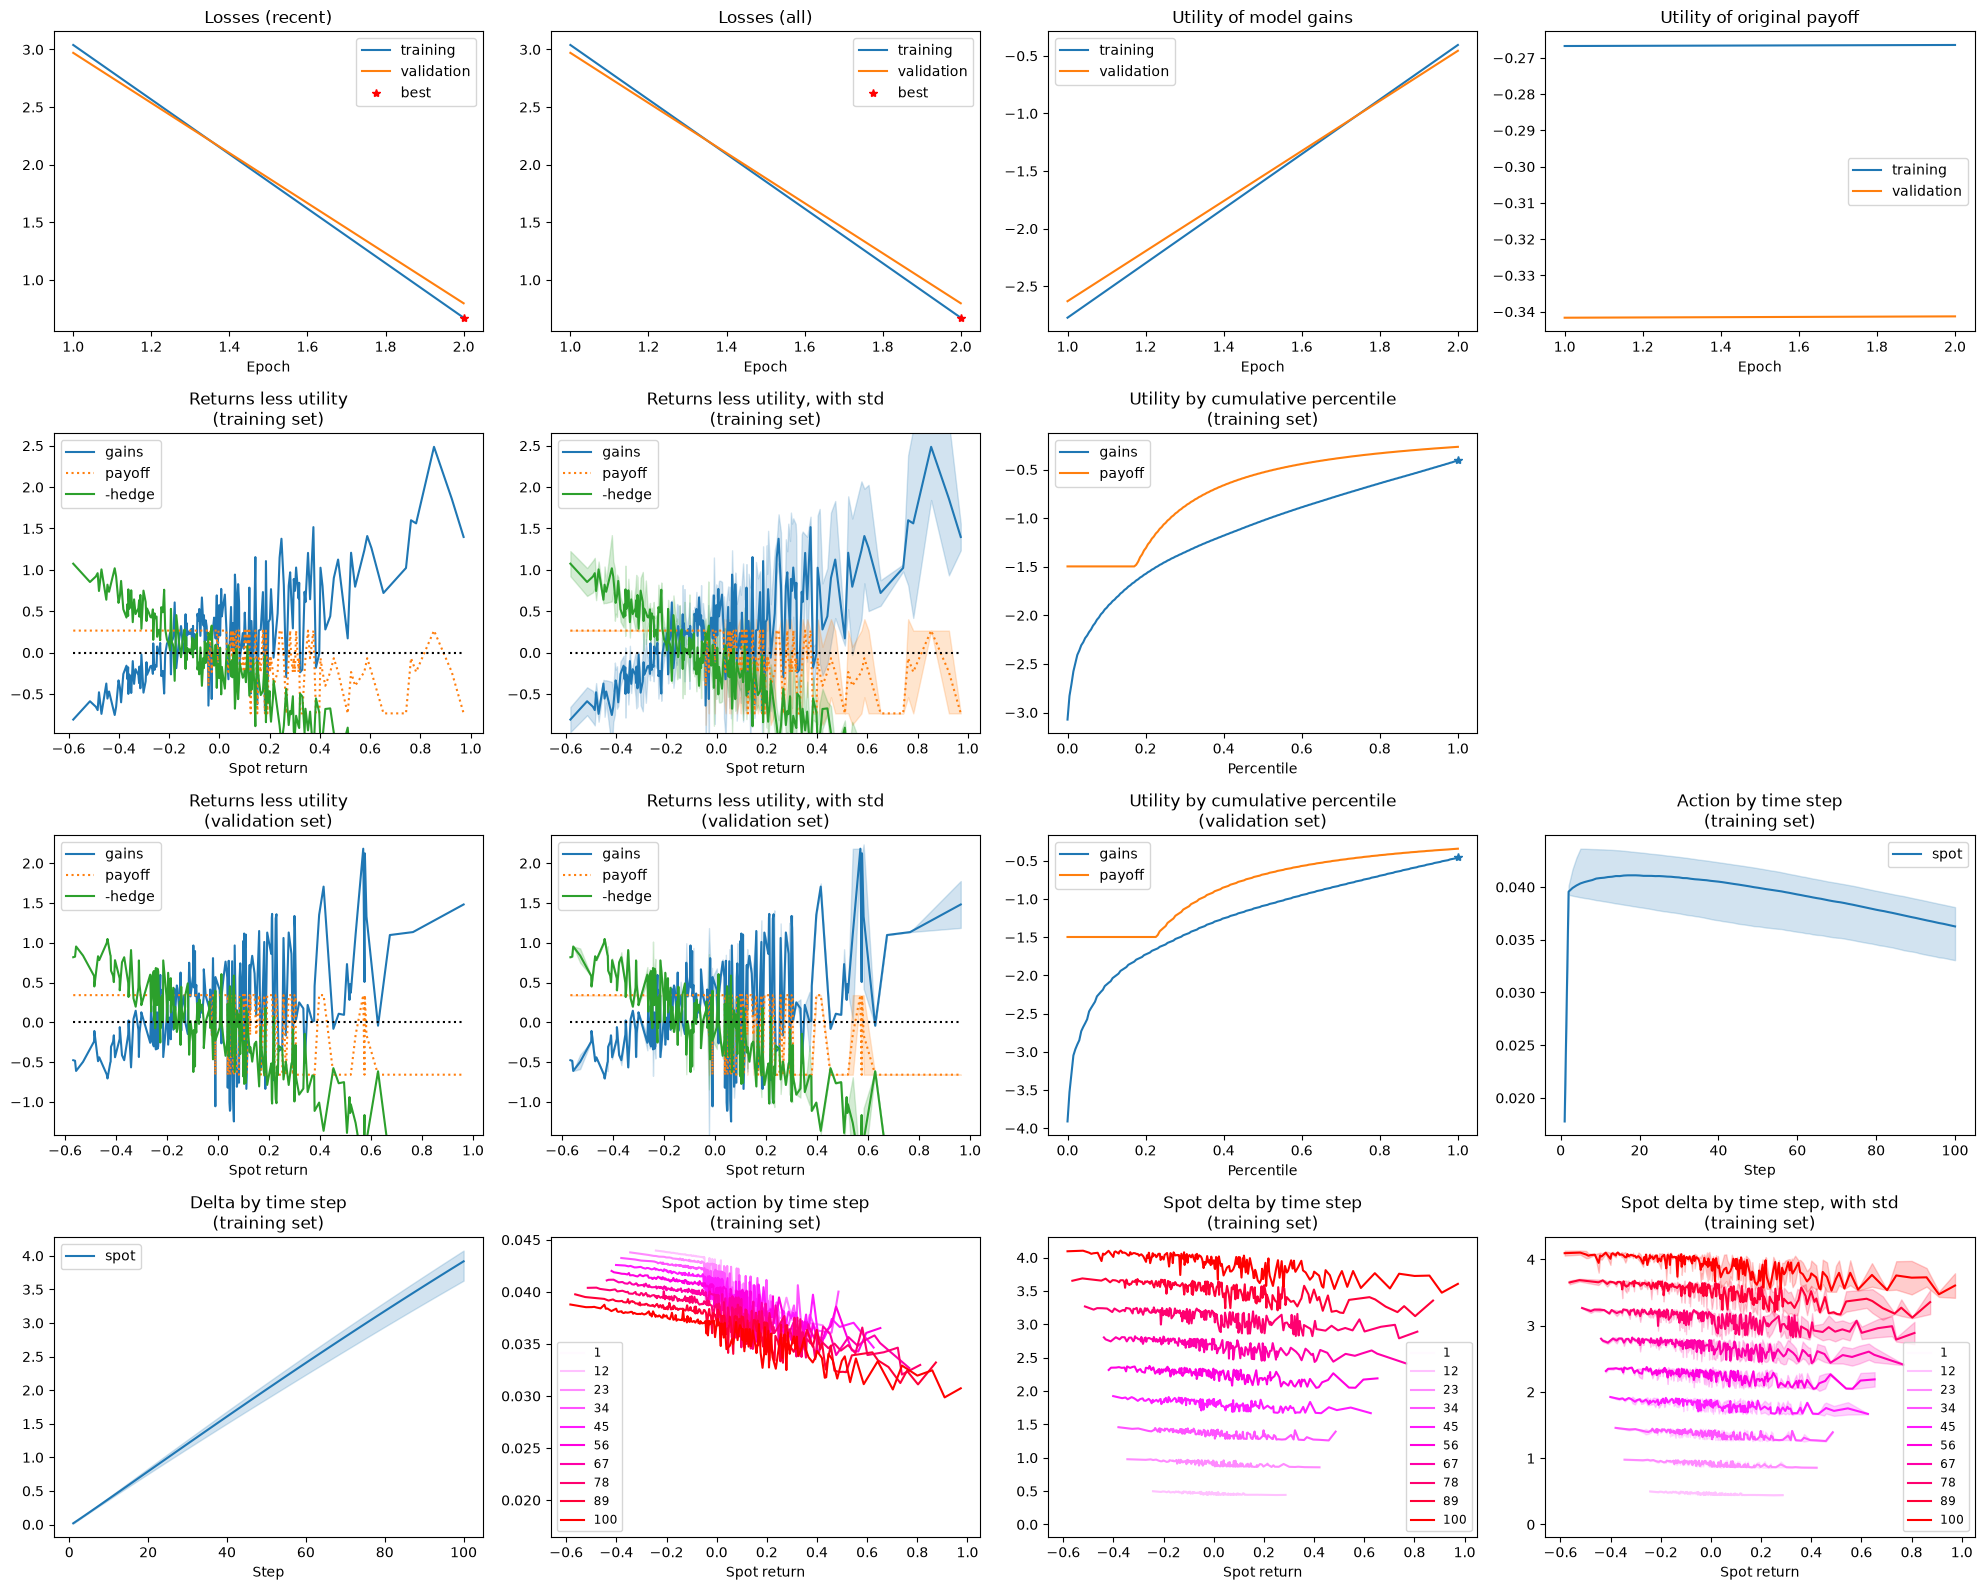

--- Training American Digital: digital (epochs=2) ---


  epoch 1/2: loss 0.52705 val 0.67646 best@1 (2.08s)


  epoch 2/2: loss 0.52550 val 0.67319 best@2 (0.42s)


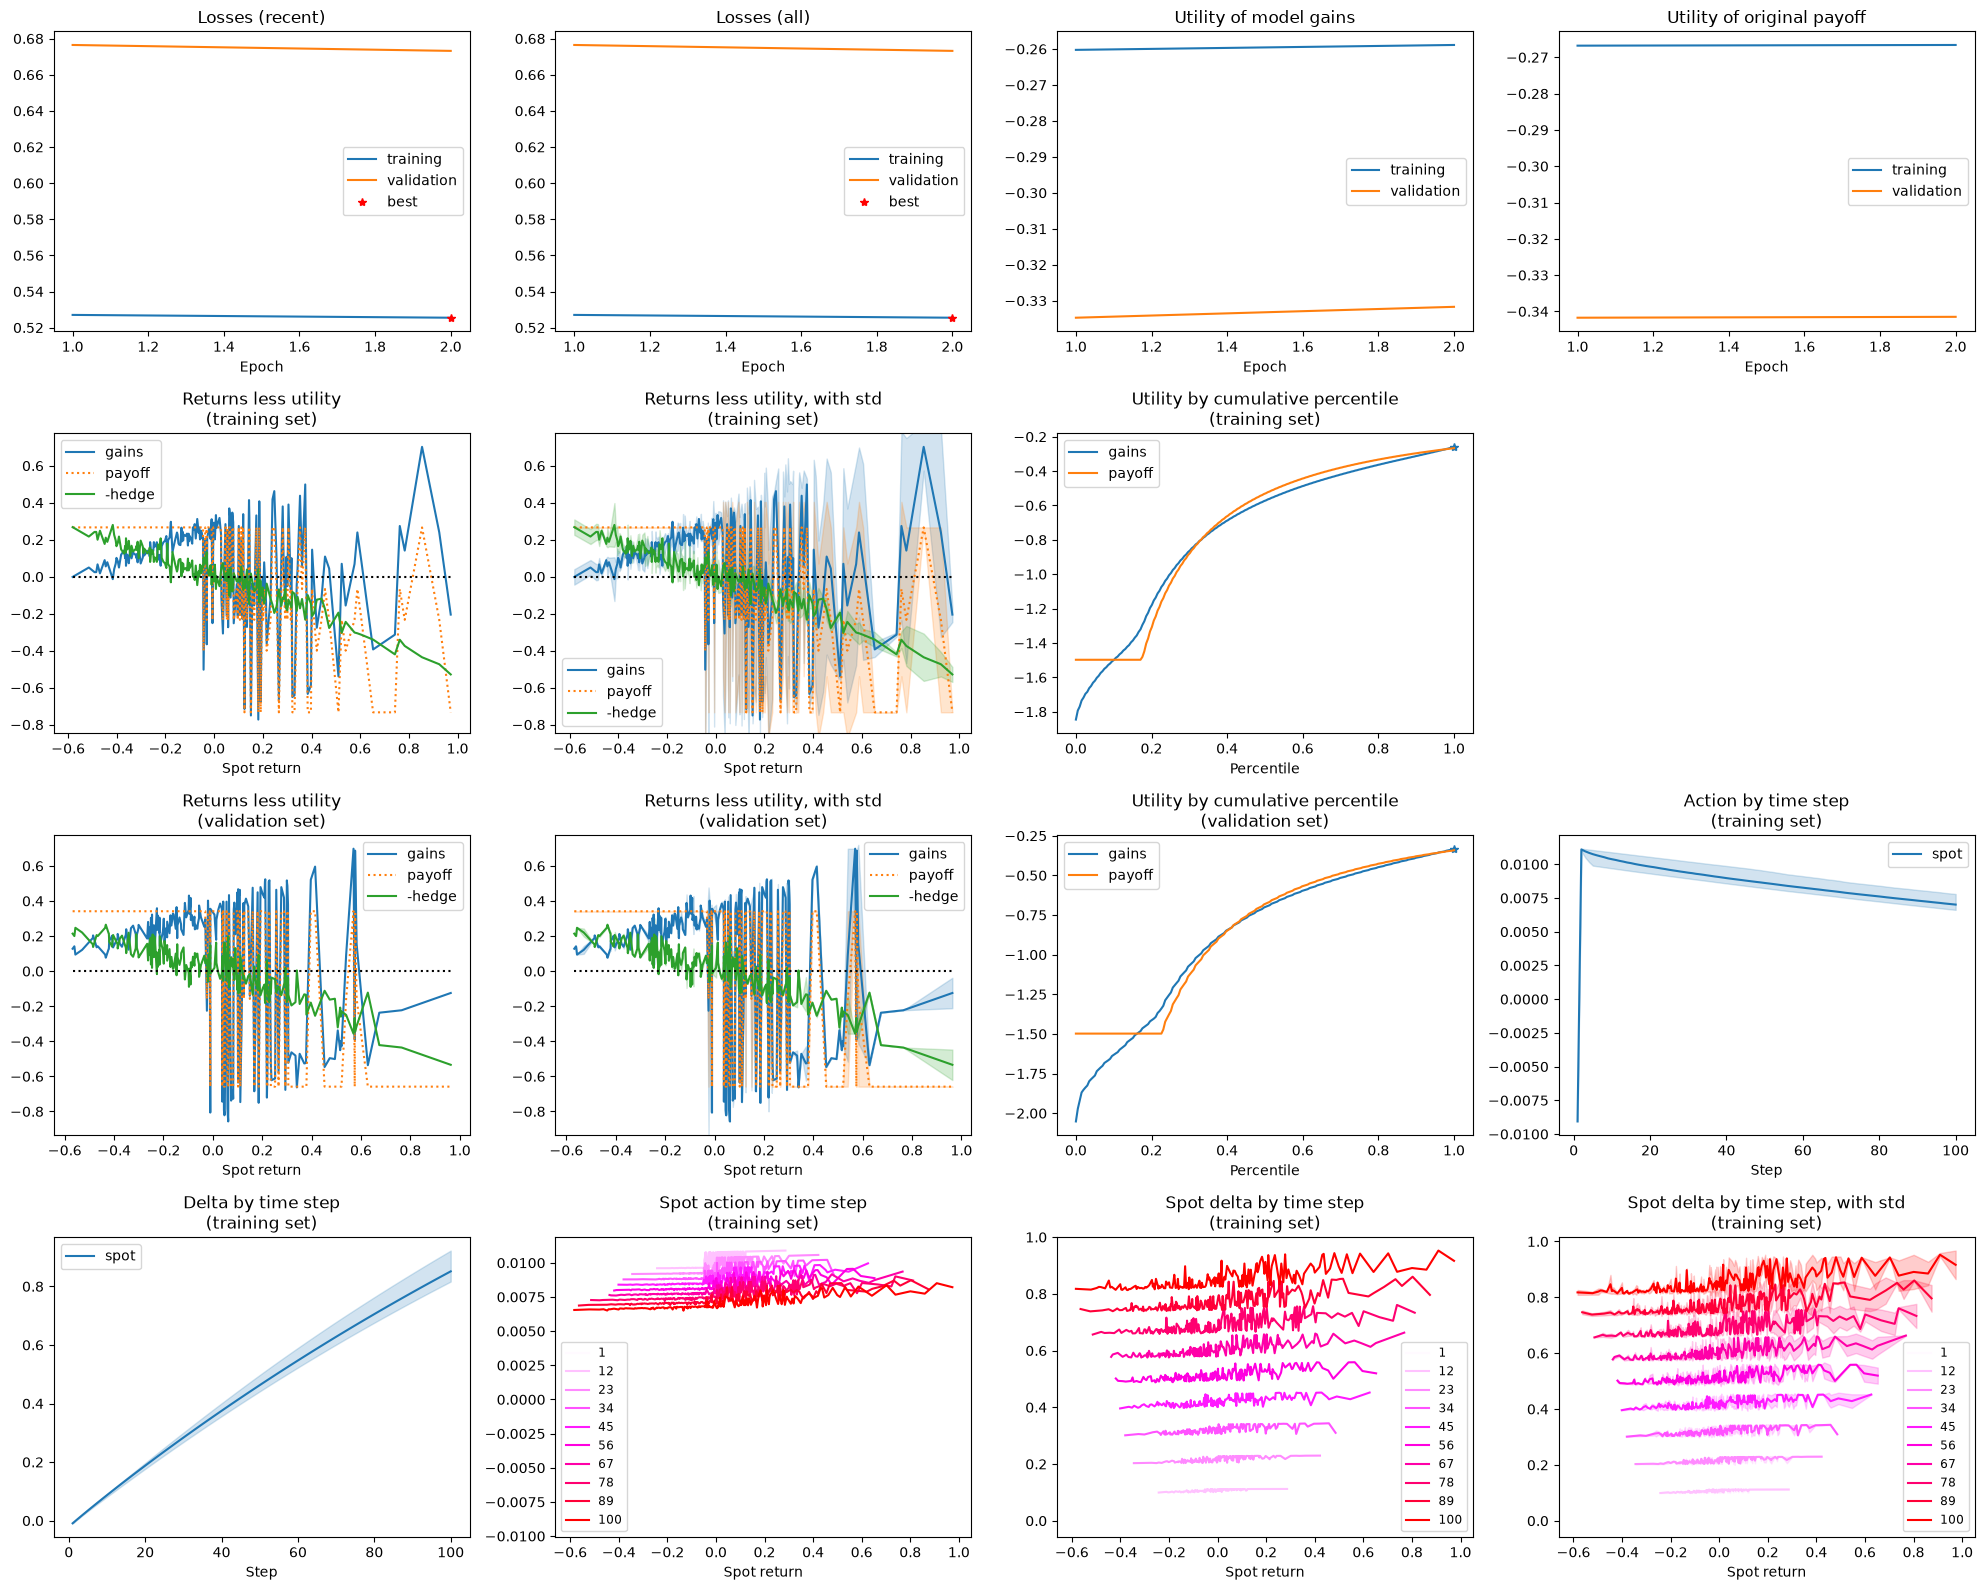

--- Training American Digital: standard (epochs=2) ---


  epoch 1/2: loss 0.56792 val 0.71747 best@1 (1.94s)


  epoch 2/2: loss 0.52733 val 0.67479 best@2 (0.40s)


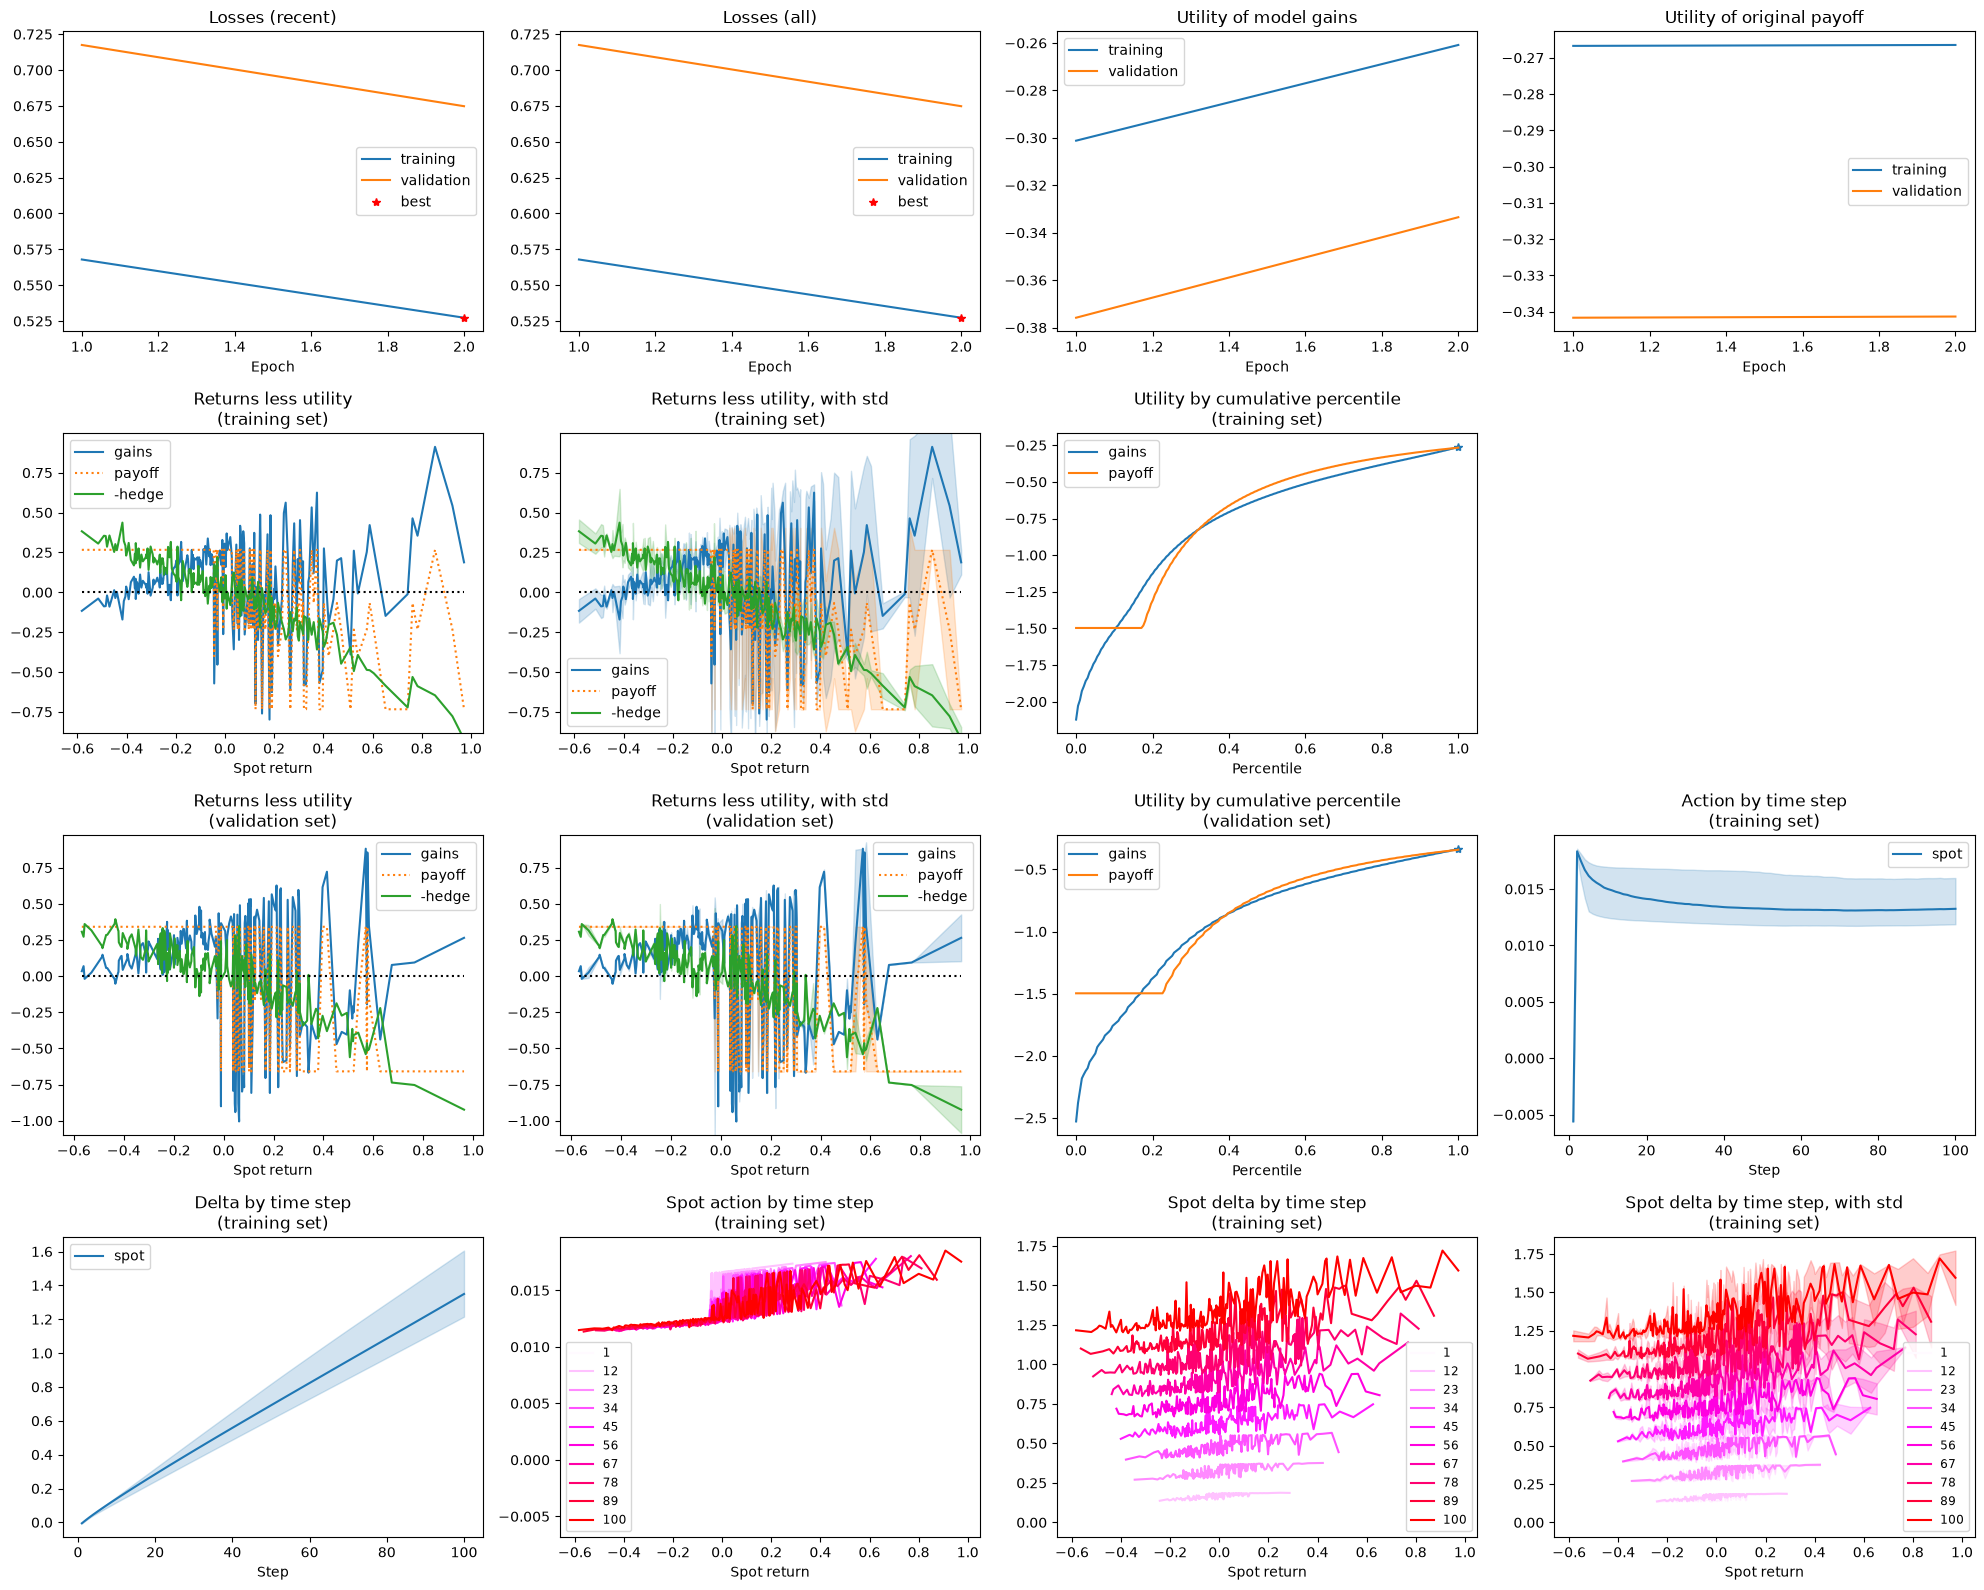

--- Training American Digital: mix_relu (epochs=2) ---


  epoch 1/2: loss 2.71242 val 2.67412 best@1 (2.00s)


  epoch 2/2: loss 1.46812 val 1.56249 best@2 (0.51s)


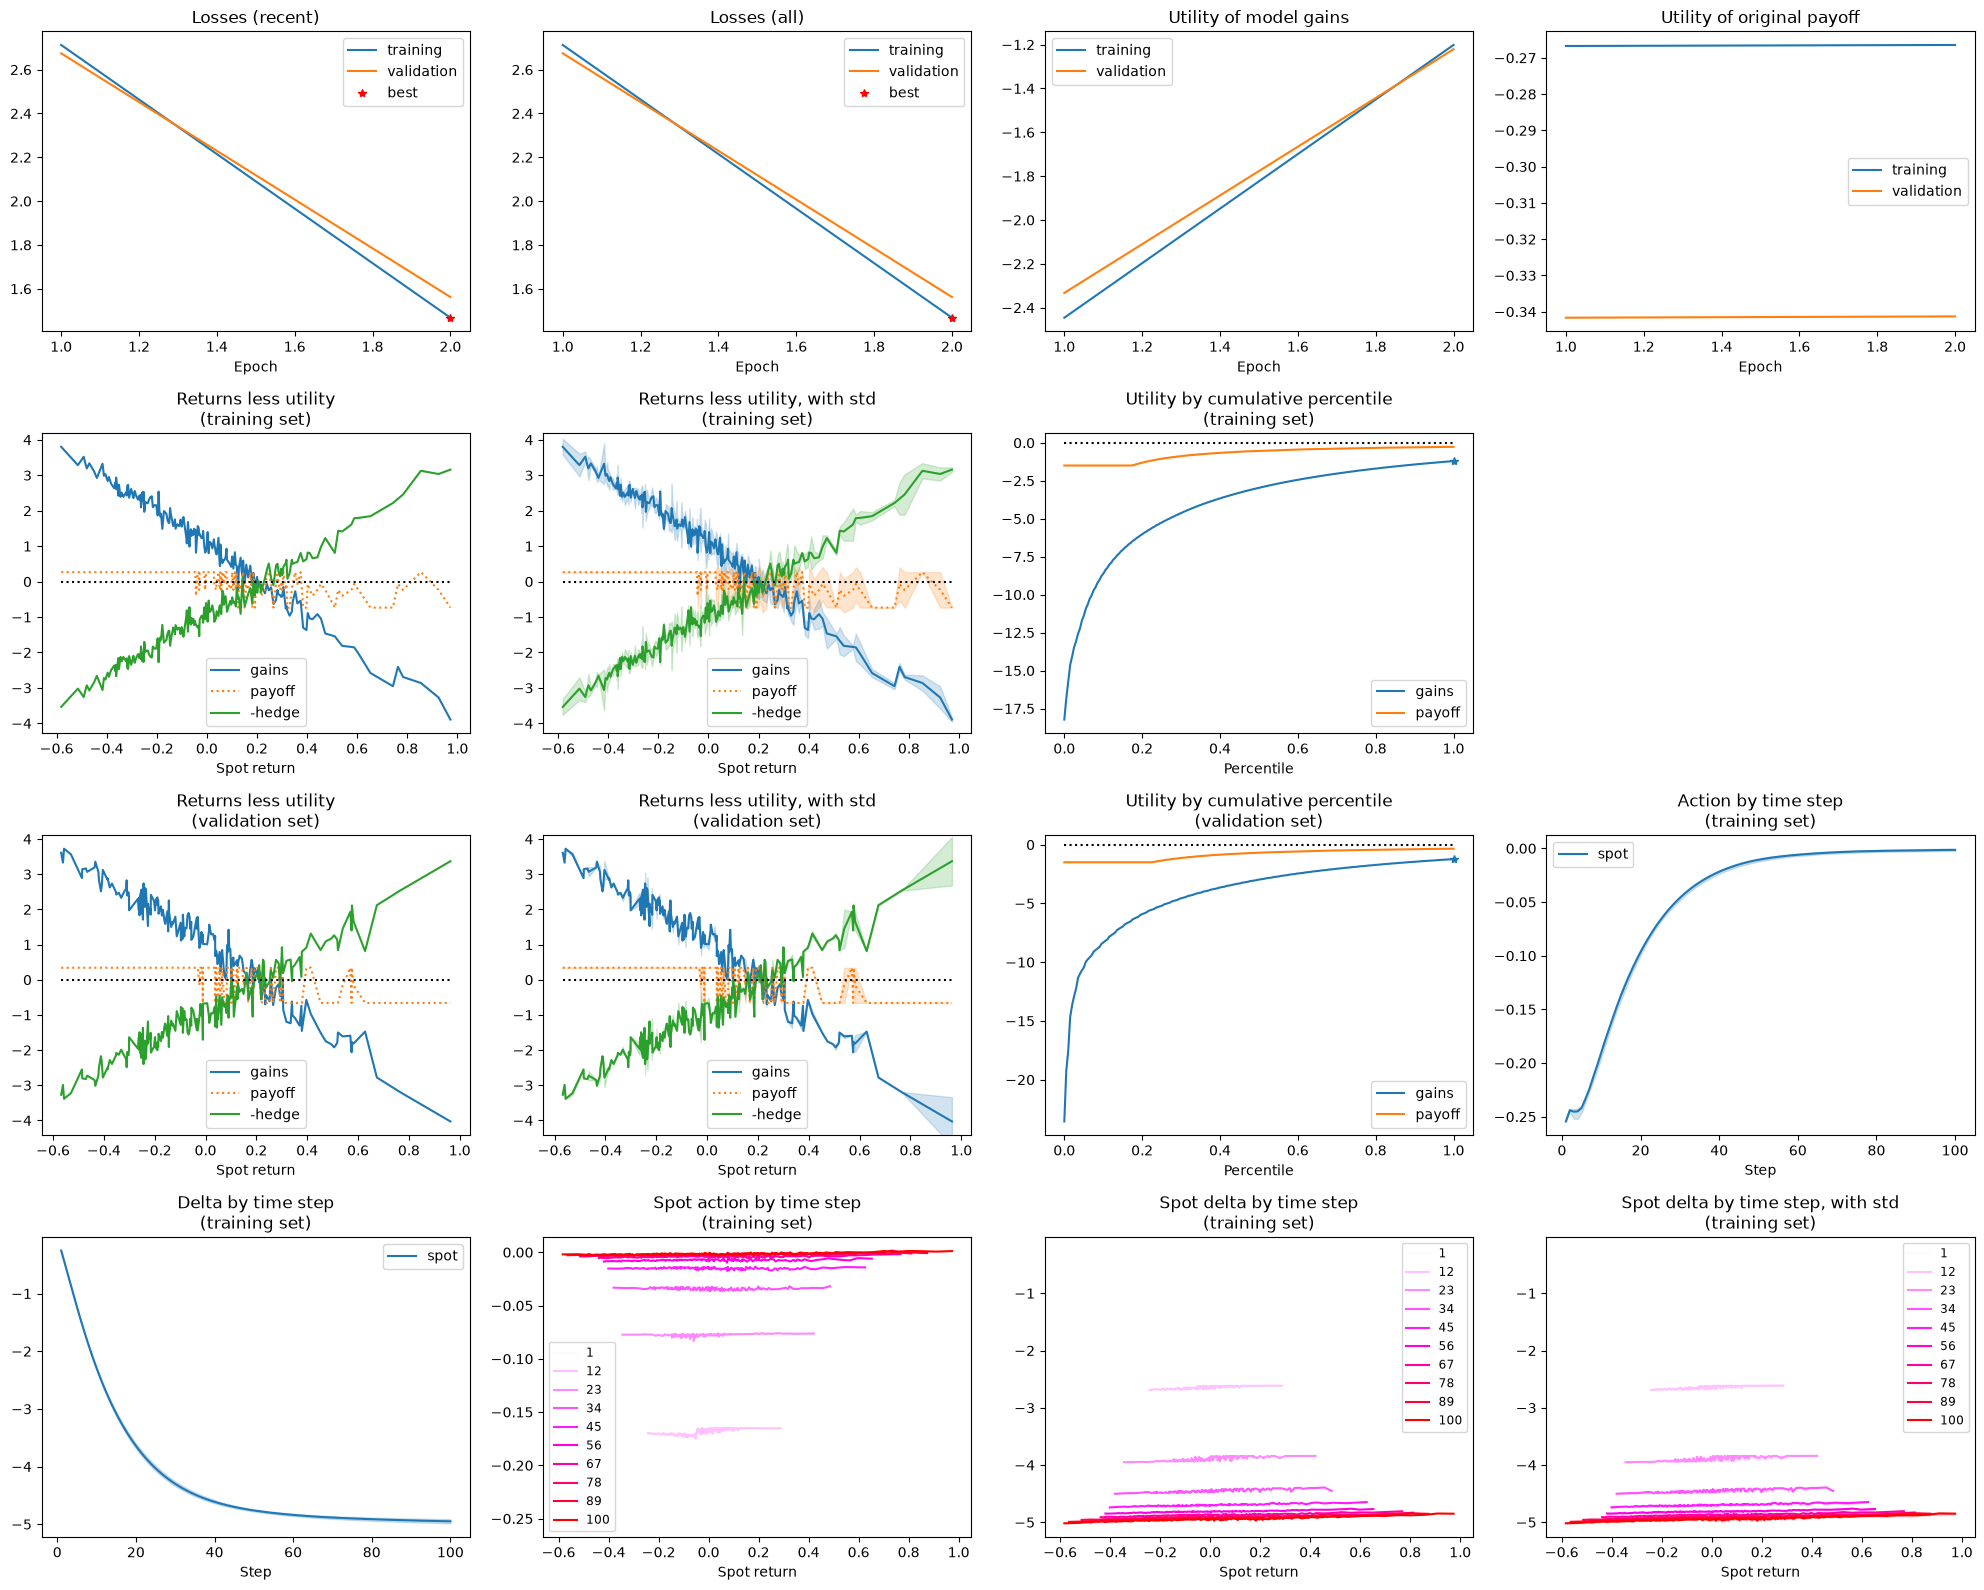

--- Training American Digital: mix_softplus (epochs=2) ---


  epoch 1/2: loss 0.59719 val 0.74429 best@1 (2.23s)


  epoch 2/2: loss 0.52210 val 0.67153 best@2 (0.88s)


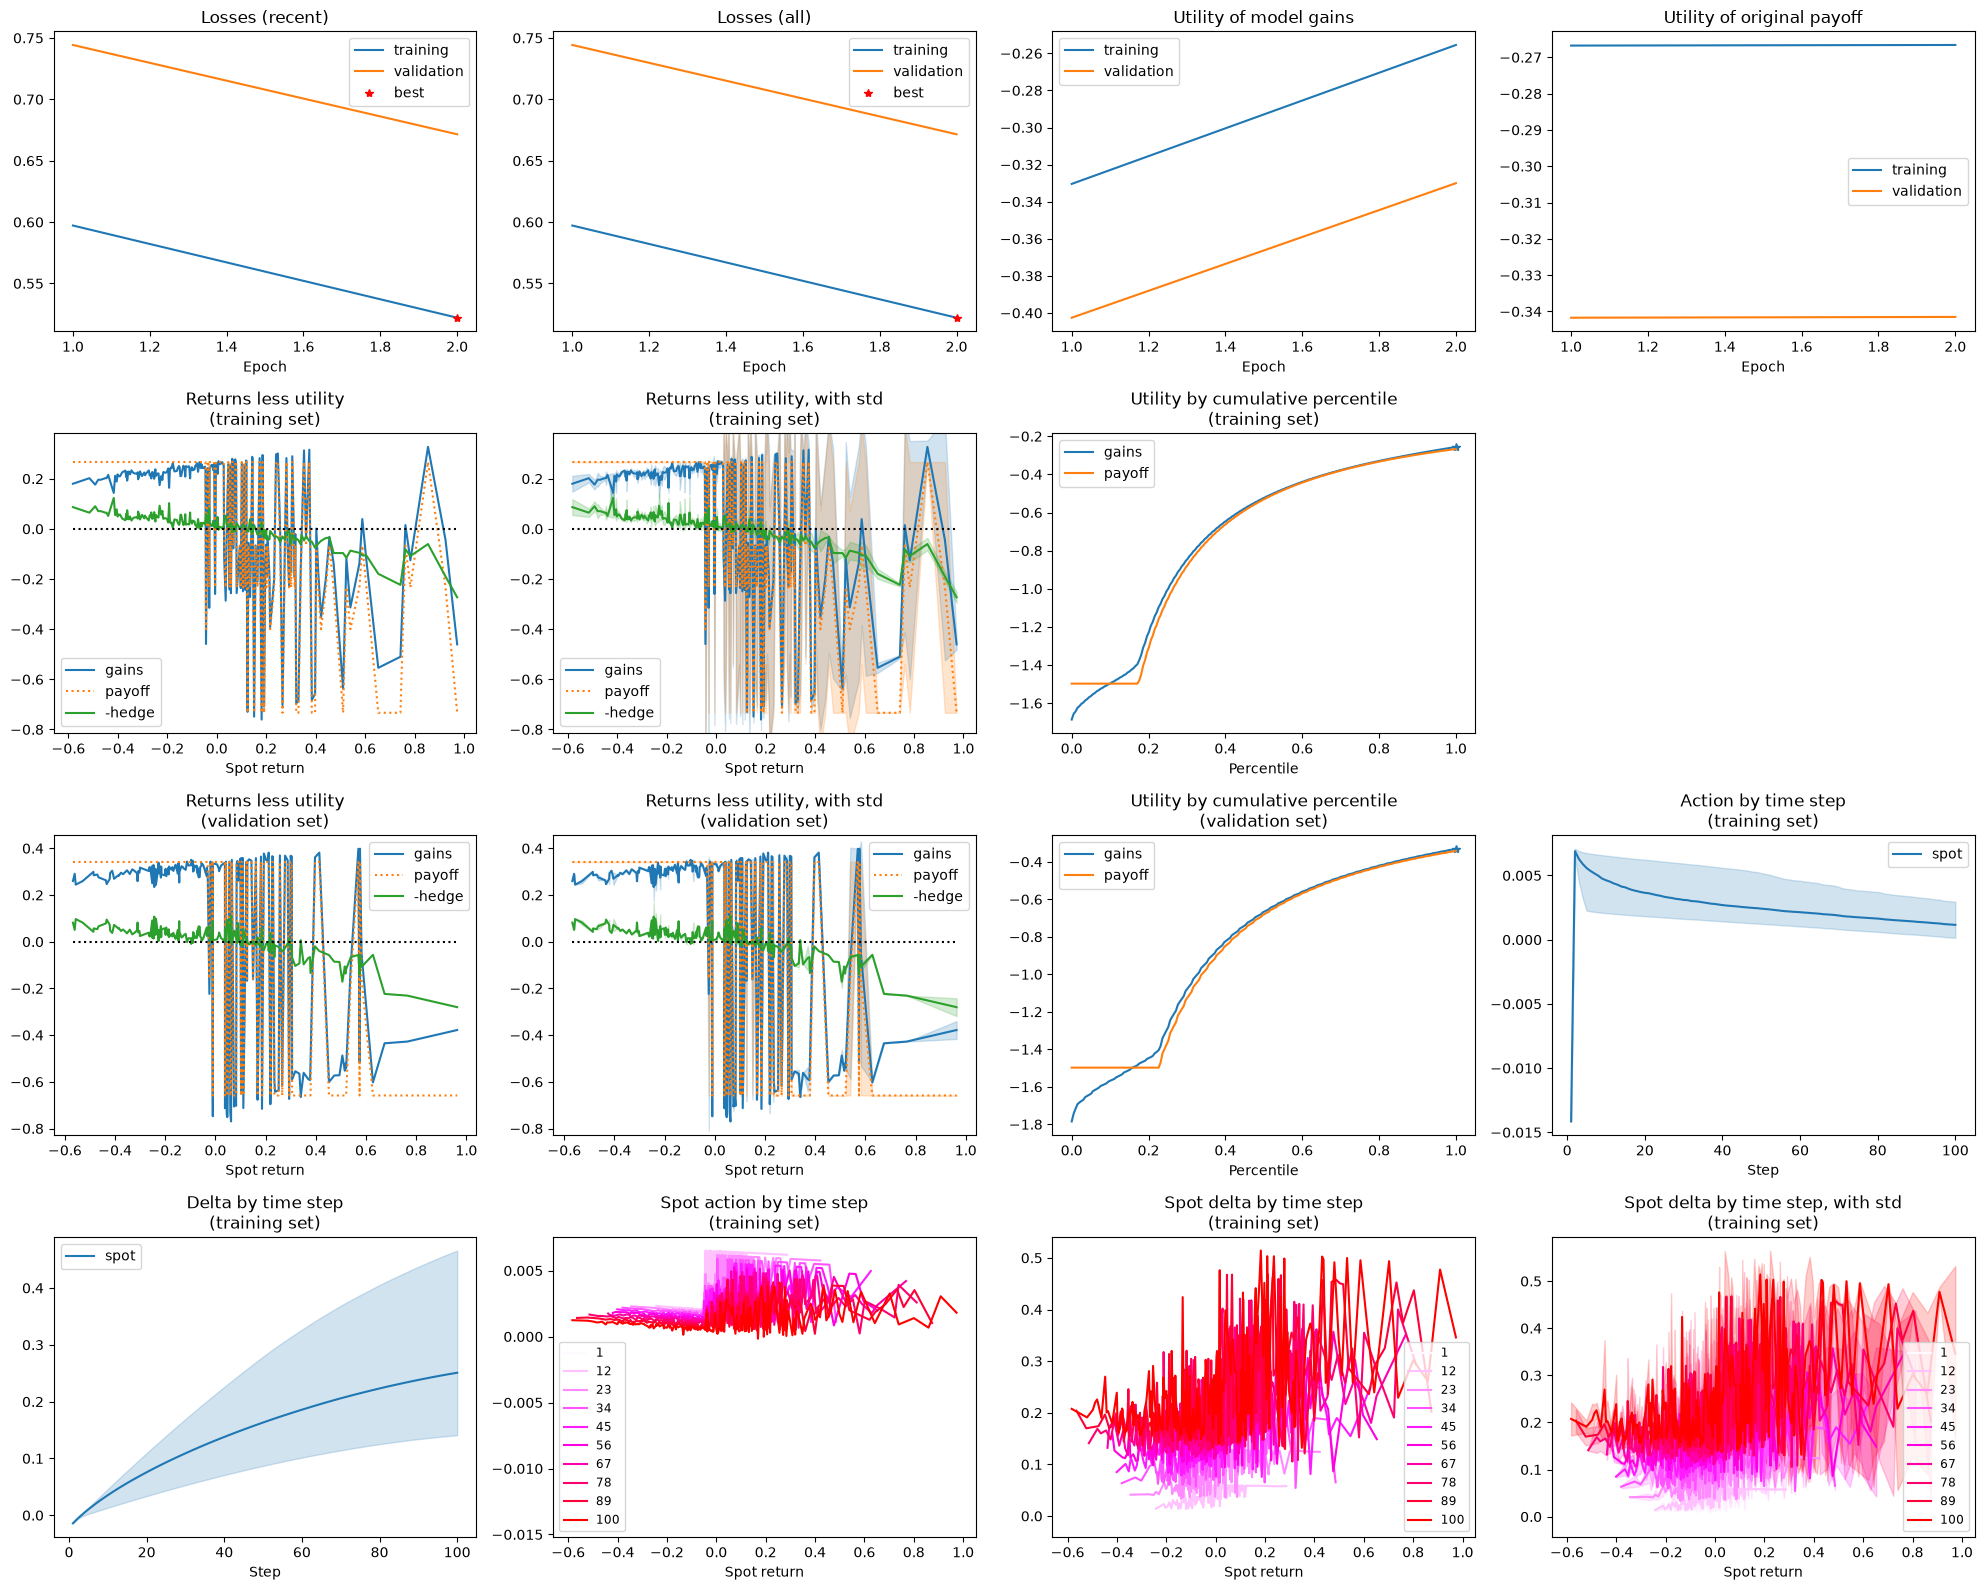

In [3]:
agent_base = AgentConfig(
    depth=cfg_ref["depth"], width=cfg_ref["width"], activation=cfg_ref["activation"],
    features=("price", "delta", "time_left", "payoff_features")
)

configs = {
    "none": replace(agent_base, classic=0, aggregate=0, past_repr=0, event=0),
    "digital": replace(agent_base, classic=0, aggregate=0, past_repr=5, event=5),
    "standard": replace(agent_base, classic=0, aggregate=5, past_repr=0, event=0),
    "mix_relu": replace(agent_base, classic=0, aggregate=2, past_repr=2, event=0, depth=5, width=100, activation="relu"),
    "mix_softplus": replace(agent_base, classic=0, aggregate=2, past_repr=2, event=0, depth=5, width=100, activation="softplus"),
}

fits = {}
for k, agent in configs.items():
    print(f"--- Training American Digital: {k} (epochs={n_epochs}) ---")
    gym = GymConfig(agent=agent, utility=cfg_ref["utility"], lmbda=cfg_ref["lmbda"])
    fits[k] = fit(gym, train_cfg, world, val_world, log_every=max(1, n_epochs // 2), checkpoint_dir=CHECKPOINTS)
    try:
        plot_training(fits[k].result, fits[k].train, fits[k].val, world, val_world)
        plt.show()
    except Exception as e:
        print(f"Plot note for {k}: {e}")


## Hedging Deltas and Terminal Profiles


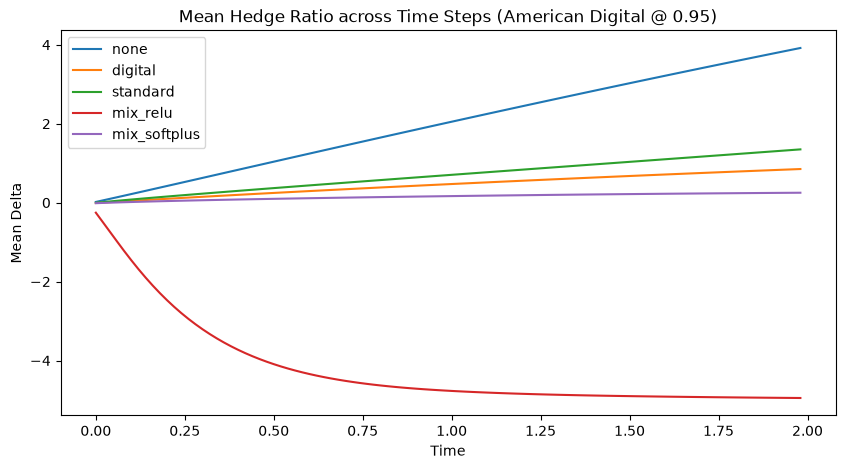

In [5]:
try:
    spots = world.spot_all
    hedges = world.market["hedges"][:, :, 0]
    nSteps = world.nSteps
    times = world.timeline
    actions = {k: fits[k].train['actions'][:, :, 0] for k in fits}
    deltas = {k: np.cumsum(actions[k], axis=1) for k in fits}

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.set_title(f"Mean Hedge Ratio across Time Steps ({payoff_def.name})")
    for k in fits:
        ax.plot(times[:-1], np.mean(deltas[k], axis=0), label=k)
    ax.set_xlabel("Time")
    ax.set_ylabel("Mean Delta")
    ax.legend()
    plt.show()
except Exception as e:
    print(f"Delta analysis note: {e}")


### Summary of American Digital Experiments
Successfully completed 5 architectural configurations for American Digital option.
